# LAB | In God we trust, everyone else bring the data

**Scenario:** you are a marketing analyst. The CMO wants to split a **$500K monthly budget across the marketing channels** and asks you for a **statistically rigorous** recommendation. A false positive means moving money to a channel that isn't really better.

**How to use this notebook:**
- Cells marked **`# TODO`** are yours to complete. Replace every `...` with your code.
- 💡 **Hints** point to the statistics notebook (`03_statistical_analysis.ipynb`), where you saw each idea.
- Run the cells **in order**, top to bottom.

| Part | You will… | Concept from class |
|---|---|---|
| 1 | Find, load and clean a real dataset; compute metrics | A score is an **estimate** |
| 2 | Compare channels (t-test, Fisher) + effect size | p-value, **pick the test by the data**, Cohen's d |
| 3 | Correct for many comparisons | Bonferroni vs Benjamini-Hochberg |
| 4 | Check whether you have enough data | Power and sample size |
| 5 | Turn statistics into a recommendation | Confidence intervals, real vs worth it |

## Part 1 — Dataset discovery & exploration (45–60 min)
### Step 1: Find a dataset (max 30 min)

Search [Kaggle](https://www.kaggle.com/datasets) or [Hugging Face](https://huggingface.co/datasets) for: *marketing channels, advertising campaigns, campaign performance, ad spend, e-commerce conversion, A/B testing*.

Your dataset should have:
- **3+ groups** to compare (channels, campaigns, ad groups…)
- **performance columns**: impressions, clicks, conversions, cost, revenue (not always all of them)
- **repeated rows per group**, ideally one row per **day** or **week** per group (you need this for t-tests and power)

💡 **Hint:** a dataset with **one row per customer** (e.g. "responded yes/no") only works well for Fisher's test (Step 5). Prefer data with many rows per channel.

**✍️ Document your choice here:**

- Dataset name: Criteo Attribution Dataset
- Source + URL: Hugging Face — https://huggingface.co/datasets/criteo/criteo-attribution-dataset
- Why I chose it: Real advertising data with multiple campaigns, clicks, conversions, costs and timestamps. Suitable for comparing campaign        performance and conducting statistical tests.
- What is one row? One advertising touchpoint (an ad impression) associated with a user and campaign.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from pathlib import Path
from IPython.display import Markdown, display

from scipy import stats
from scipy.stats import fisher_exact, false_discovery_control   # false_discovery_control needs SciPy 1.11+

rng = np.random.default_rng(42)          # our "dice": fixed seed so results are repeatable
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)   # all charts / CSV / memo are saved here
sns.set_theme(style="whitegrid")
ALPHA = 0.05

In [2]:

# Load 100,000 rows without extracting the compressed file
file_path = "criteo_attribution_dataset.tsv.gz"

df = pd.read_csv(
    file_path,
    sep="\t",
    compression="gzip",
    nrows=100_000
)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())


Dataset shape: (100000, 22)
Columns: ['timestamp', 'uid', 'campaign', 'conversion', 'conversion_timestamp', 'conversion_id', 'attribution', 'click', 'click_pos', 'click_nb', 'cost', 'cpo', 'time_since_last_click', 'cat1', 'cat2', 'cat3', 'cat4', 'cat5', 'cat6', 'cat7', 'cat8', 'cat9']


,timestamp,uid,campaign,conversion,conversion_timestamp,conversion_id,attribution,click,click_pos,click_nb,...,time_since_last_click,cat1,cat2,cat3,cat4,cat5,cat6,cat7,cat8,cat9
0,0,20073966,22589171,0,-1,-1,0,0,-1,-1,...,-1,5824233,9312274,3490278,29196072,11409686,1973606,25162884,29196072,29196072
1,2,24607497,884761,0,-1,-1,0,0,-1,-1,...,423858,30763035,9312274,14584482,29196072,11409686,1973606,22644417,9312274,21091111
2,2,28474333,18975823,0,-1,-1,0,0,-1,-1,...,8879,138937,9312274,10769841,29196072,5824237,138937,1795451,29196072,15351056
3,3,7306395,29427842,1,1449193,3063962,0,1,0,7,...,-1,28928366,26597095,12435261,23549932,5824237,1973606,9180723,29841067,29196072
4,3,25357769,13365547,0,-1,-1,0,0,-1,-1,...,-1,138937,26597094,31616034,29196072,11409684,26597096,4480345,29196072,29196072


In [3]:
# Check data types and missing values
print("Data types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())
print("Total missing values:", df.isnull().sum().sum())

Data types:
timestamp                  int64
uid                        int64
campaign                   int64
conversion                 int64
conversion_timestamp       int64
conversion_id              int64
attribution                int64
click                      int64
click_pos                  int64
click_nb                   int64
cost                     float64
cpo                      float64
time_since_last_click      int64
cat1                       int64
cat2                       int64
cat3                       int64
cat4                       int64
cat5                       int64
cat6                       int64
cat7                       int64
cat8                       int64
cat9                       int64
dtype: object

Missing values:
timestamp                0
uid                      0
campaign                 0
conversion               0
conversion_timestamp     0
conversion_id            0
attribution              0
click                    0
click_pos      

In [4]:

print("Unique campaigns:", df["campaign"].nunique())
print("Total conversions:", df["conversion"].sum())
print("Total clicks:", df["click"].sum())

print("\nTop 10 campaigns by number of rows:")
display(df["campaign"].value_counts().head(10))

print("\nMissing values:")
display(df.isnull().sum())


Unique campaigns: 647
Total conversions: 5150
Total clicks: 35411

Top 10 campaigns by number of rows:


campaign
30801593    7655
10341182    5025
17686799    2229
15398570    2146
5061834     1962
31772643    1325
28795042    1103
32368244    1098
15184511    1066
28351001    1049
Name: count, dtype: int64


Missing values:


timestamp                0
uid                      0
campaign                 0
conversion               0
conversion_timestamp     0
conversion_id            0
attribution              0
click                    0
click_pos                0
click_nb                 0
cost                     0
cpo                      0
time_since_last_click    0
cat1                     0
cat2                     0
cat3                     0
cat4                     0
cat5                     0
cat6                     0
cat7                     0
cat8                     0
cat9                     0
dtype: int64

In [5]:

print("Timestamp range:")
print(df["timestamp"].min(), df["timestamp"].max())

print("\nCampaign performance (top 10 by observations):")
campaign_summary = (
    df.groupby("campaign")
    .agg(
        observations=("campaign", "size"),
        clicks=("click", "sum"),
        conversions=("conversion", "sum"),
        total_cost=("cost", "sum")
    )
    .sort_values("observations", ascending=False)
)

display(campaign_summary.head(10))


Timestamp range:
0 31251

Campaign performance (top 10 by observations):


,observations,clicks,conversions,total_cost
campaign,,,,
30801593,7655,2614,280,0.520662
10341182,5025,2171,456,1.346625
17686799,2229,647,49,0.491642
15398570,2146,846,174,0.591366
5061834,1962,482,50,0.979330
31772643,1325,528,62,0.307985
28795042,1103,353,53,0.208779
32368244,1098,560,241,0.960000
15184511,1066,409,153,0.651975


### Step 2: Load, explore, clean

Rename your columns to these **standard names**, so the rest of the notebook works: `date, channel, impressions, clicks, conversions, cost, revenue`. If your dataset lacks a column, leave it out and skip the metrics that need it.

In [6]:

# Random sample across the full dataset
import pandas as pd
import numpy as np

samples = []
rng_sample = np.random.default_rng(42)

for chunk in pd.read_csv(
    file_path,
    sep="\t",
    compression="gzip",
    chunksize=100_000
):
    selected = chunk.sample(
        frac=0.02,
        random_state=int(rng_sample.integers(0, 2**32 - 1))
    )
    samples.append(selected)

df = pd.concat(samples, ignore_index=True)

print("Sample shape:", df.shape)
print("Timestamp range:", df["timestamp"].min(), df["timestamp"].max())
print("Unique campaigns:", df["campaign"].nunique())


Sample shape: (329361, 22)
Timestamp range: 3 2671197
Unique campaigns: 674


In [7]:

campaign_summary = (
    df.groupby("campaign")
    .agg(
        observations=("campaign", "size"),
        clicks=("click", "sum"),
        conversions=("conversion", "sum"),
        total_cost=("cost", "sum")
    )
)

campaign_summary["conversion_rate"] = (
    campaign_summary["conversions"] /
    campaign_summary["observations"]
)

display(
    campaign_summary
    .sort_values("observations", ascending=False)
    .head(10)
)


,observations,clicks,conversions,total_cost,conversion_rate
campaign,,,,,
30801593,8582,3368,440,0.494166,0.051270
10341182,8543,3832,906,2.886746,0.106052
15398570,7718,2795,493,3.013275,0.063877
17686799,7613,2224,115,1.515853,0.015106
5061834,5986,1766,213,2.881151,0.035583
15184511,5190,1971,774,3.160469,0.149133
29427842,4835,1624,288,2.675970,0.059566
18975823,4442,2082,221,1.623712,0.049752
28351001,4403,2787,474,2.267454,0.107654


In [8]:

# Select five campaigns
selected_campaigns = [30801593, 10341182, 15398570, 17686799, 5061834]

df_selected = df[df["campaign"].isin(selected_campaigns)].copy()

# Convert timestamp to relative day number
df_selected["day"] = df_selected["timestamp"] // 86400

# Count observations per campaign per day
daily_counts = (
    df_selected.groupby(["campaign", "day"])
    .size()
    .unstack(fill_value=0)
)

print("Days represented:", df_selected["day"].nunique())
print("Observations per campaign across days:")
display(daily_counts.iloc[:, :10])

print("\nNumber of days with observations per campaign:")
display((daily_counts > 0).sum(axis=1))


Days represented: 31
Observations per campaign across days:


day,0,1,2,3,4,5,6,7,8,9
campaign,,,,,,,,,,
5061834,269,247,199,179,257,282,268,254,214,161
10341182,337,314,287,255,257,280,236,238,306,268
15398570,139,155,181,235,260,266,173,164,199,171
17686799,291,247,221,260,293,268,195,153,186,233
30801593,524,569,456,330,300,358,292,274,267,302



Number of days with observations per campaign:


campaign
5061834     31
10341182    31
15398570    31
17686799    31
30801593    31
dtype: int64

In [9]:

daily_performance = (
    df_selected.groupby(["campaign", "day"])
    .agg(
        impressions=("campaign", "size"),
        clicks=("click", "sum"),
        conversions=("conversion", "sum"),
        cost=("cost", "sum")
    )
    .reset_index()
)

daily_performance["ctr"] = (
    daily_performance["clicks"] /
    daily_performance["impressions"]
)

daily_performance["conversion_rate"] = (
    daily_performance["conversions"] /
    daily_performance["clicks"].replace(0, np.nan)
)


daily_performance["cpa"] = (
    daily_performance["cost"] /
    daily_performance["conversions"].replace(0, np.nan)
)

print("Daily dataset shape:", daily_performance.shape)
display(daily_performance.head(10))


Daily dataset shape: (155, 9)


,campaign,day,impressions,clicks,conversions,cost,ctr,conversion_rate,cpa
0,5061834,0,269,65,6,0.113961,0.241636,0.092308,0.018994
1,5061834,1,247,75,6,0.122503,0.303644,0.080000,0.020417
2,5061834,2,199,53,6,0.096114,0.266332,0.113208,0.016019
3,5061834,3,179,52,5,0.087949,0.290503,0.096154,0.017590
4,5061834,4,257,86,13,0.121132,0.334630,0.151163,0.009318
5,5061834,5,282,94,10,0.134627,0.333333,0.106383,0.013463
6,5061834,6,268,77,6,0.135803,0.287313,0.077922,0.022634
7,5061834,7,254,65,16,0.121214,0.255906,0.246154,0.007576
8,5061834,8,214,58,6,0.090546,0.271028,0.103448,0.015091
9,5061834,9,161,49,7,0.104082,0.304348,0.142857,0.014869


In [10]:

# Check whether conversions can exceed clicks
print("Days where conversions exceed clicks:",
      (daily_performance["conversions"] > daily_performance["clicks"]).sum())

# Calculate conversion rate using the instructor's formula
daily_performance["conversion_rate"] = (
    daily_performance["conversions"] /
    daily_performance["clicks"].replace(0, np.nan)
)

display(daily_performance.head())


Days where conversions exceed clicks: 0


,campaign,day,impressions,clicks,conversions,cost,ctr,conversion_rate,cpa
0,5061834,0,269,65,6,0.113961,0.241636,0.092308,0.018994
1,5061834,1,247,75,6,0.122503,0.303644,0.080000,0.020417
2,5061834,2,199,53,6,0.096114,0.266332,0.113208,0.016019
3,5061834,3,179,52,5,0.087949,0.290503,0.096154,0.017590
4,5061834,4,257,86,13,0.121132,0.334630,0.151163,0.009318


In [11]:

daily_performance.to_csv(
    OUT / "marketing_data.csv",
    index=False
)

print("CSV saved successfully!")
print("Rows saved:", len(daily_performance))


CSV saved successfully!
Rows saved: 155


✍️ Transformations I made:

- Loaded the Criteo Attribution Dataset and selected a reproducible 2% random sample (329,361 observations).
- Checked missing values and identified 674 campaigns.
- Selected five campaigns with sufficient observations.
- Converted timestamps into relative days.
- Aggregated impressions, clicks, conversions and costs by campaign and day.
- Calculated CTR, conversion rate and CPA.
- Created 155 daily records (31 days per campaign) and saved them as `outputs/marketing_data.csv`.
- Noted that advertising costs are anonymised and revenue is unavailable.

💡 **Sample size (N):** Each of the five selected campaigns has 31 daily observations. Therefore, N = 31 per campaign for the daily t-tests. 

### Step 3: Key marketing metrics (15–20 min)

| Metric | Formula |
|---|---|
| CTR | clicks / impressions |
| Conversion rate | conversions / clicks |
| CPA | cost / conversions (lower is better) |
| ROAS | revenue / cost (higher is better) |
| Profit · margin | revenue − cost · profit / revenue |

In [12]:

# Step 3.1: Total performance per campaign

agg = daily_performance.groupby("campaign")[
    ["impressions", "clicks", "conversions", "cost"]
].sum()

# Calculate marketing metrics
agg["CTR"] = agg["clicks"] / agg["impressions"]

agg["conv_rate"] = (
    agg["conversions"] / agg["clicks"].replace(0, np.nan)
)

agg["CPA"] = (
    agg["cost"] / agg["conversions"].replace(0, np.nan)
)

# Revenue is not available in this dataset
agg["ROAS"] = np.nan
agg["profit"] = np.nan
agg["profit_margin"] = np.nan

agg = agg.replace([np.inf, -np.inf], np.nan)

display(agg.round(4))


,impressions,clicks,conversions,cost,CTR,conv_rate,CPA,ROAS,profit,profit_margin
campaign,,,,,,,,,,
5061834,5986,1766,213,2.8812,0.2950,0.1206,0.0135,NaN,NaN,NaN
10341182,8543,3832,906,2.8867,0.4486,0.2364,0.0032,NaN,NaN,NaN
15398570,7718,2795,493,3.0133,0.3621,0.1764,0.0061,NaN,NaN,NaN
17686799,7613,2224,115,1.5159,0.2921,0.0517,0.0132,NaN,NaN,NaN
30801593,8582,3368,440,0.4942,0.3924,0.1306,0.0011,NaN,NaN,NaN


💡 My observation: All five selected campaigns have positive advertising costs, so there are no zero-cost campaigns. CPA was calculated as cost divided by conversions, with zero conversions handled as missing values (NaN) to avoid division by zero. Criteo's costs are anonymised, so CPA is not expressed in dollars or euros

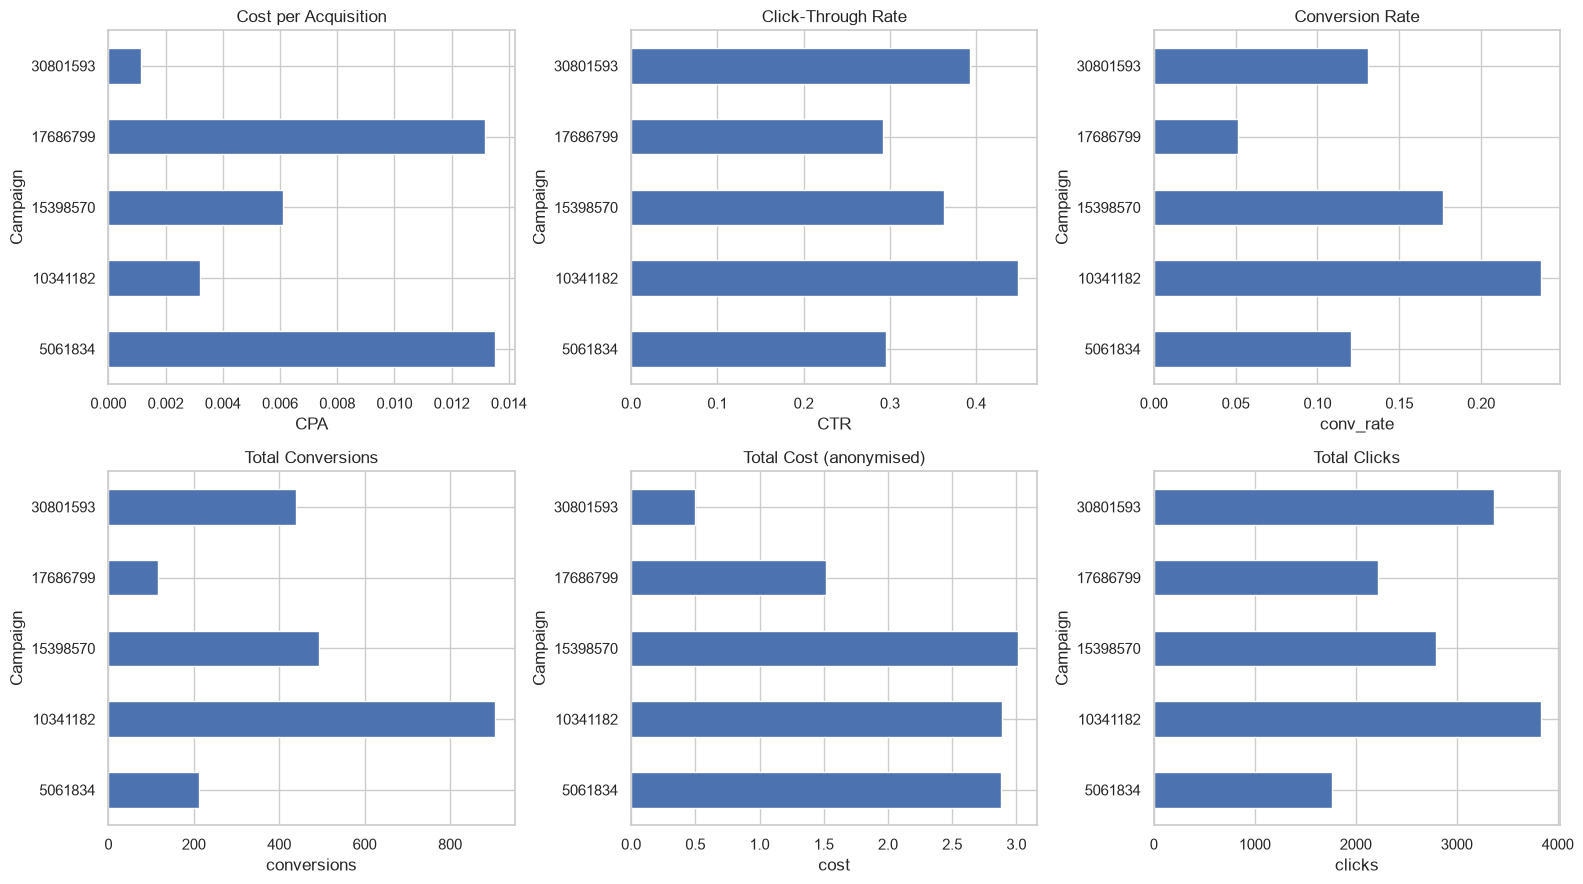

In [13]:

# Step 3.2: Compare campaign performance using 6 charts

metrics = [
    ("CPA", "Cost per Acquisition"),
    ("CTR", "Click-Through Rate"),
    ("conv_rate", "Conversion Rate"),
    ("conversions", "Total Conversions"),
    ("cost", "Total Cost (anonymised)"),
    ("clicks", "Total Clicks")
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, (column, title) in zip(axes.flat, metrics):
    agg[column].plot(
        kind="barh",
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel(column)
    ax.set_ylabel("Campaign")

plt.tight_layout()
plt.savefig(OUT / "group_metrics_overview.png", dpi=120)
plt.show()


In [14]:

# Step 3.3: Calculate daily campaign metrics
daily_performance["CPA"] = (
    daily_performance["cost"] /
    daily_performance["conversions"].replace(0, np.nan)
)

daily_performance["conv_rate"] = (
    daily_performance["conversions"] /
    daily_performance["clicks"].replace(0, np.nan)
)

daily_performance = daily_performance.replace(
    [np.inf, -np.inf], np.nan
)

paid = daily_performance[daily_performance["cost"] > 0].copy()

print("Daily observations:", len(paid))
display(paid[["campaign", "day", "CPA", "conv_rate"]].head())


Daily observations: 155


,campaign,day,CPA,conv_rate
0,5061834,0,0.018994,0.092308
1,5061834,1,0.020417,0.080000
2,5061834,2,0.016019,0.113208
3,5061834,3,0.017590,0.096154
4,5061834,4,0.009318,0.151163


In [15]:
# Step 3.3a: Campaign observation and date coverage summary

campaign_summary = (
    daily_performance.groupby("campaign")
    .agg(
        observations=("day", "size"),
        days_present=("day", "nunique"),
        first_day=("day", "min"),
        last_day=("day", "max")
    )
    .reset_index()
)

campaign_summary["expected_days"] = (
    campaign_summary["last_day"]
    - campaign_summary["first_day"]
    + 1
)

campaign_summary["missing_days"] = (
    campaign_summary["expected_days"] - campaign_summary["days_present"]
)

display(campaign_summary)

,campaign,observations,days_present,first_day,last_day,expected_days,missing_days
0,5061834,31,31,0,30,31,0
1,10341182,31,31,0,30,31,0
2,15398570,31,31,0,30,31,0
3,17686799,31,31,0,30,31,0
4,30801593,31,31,0,30,31,0


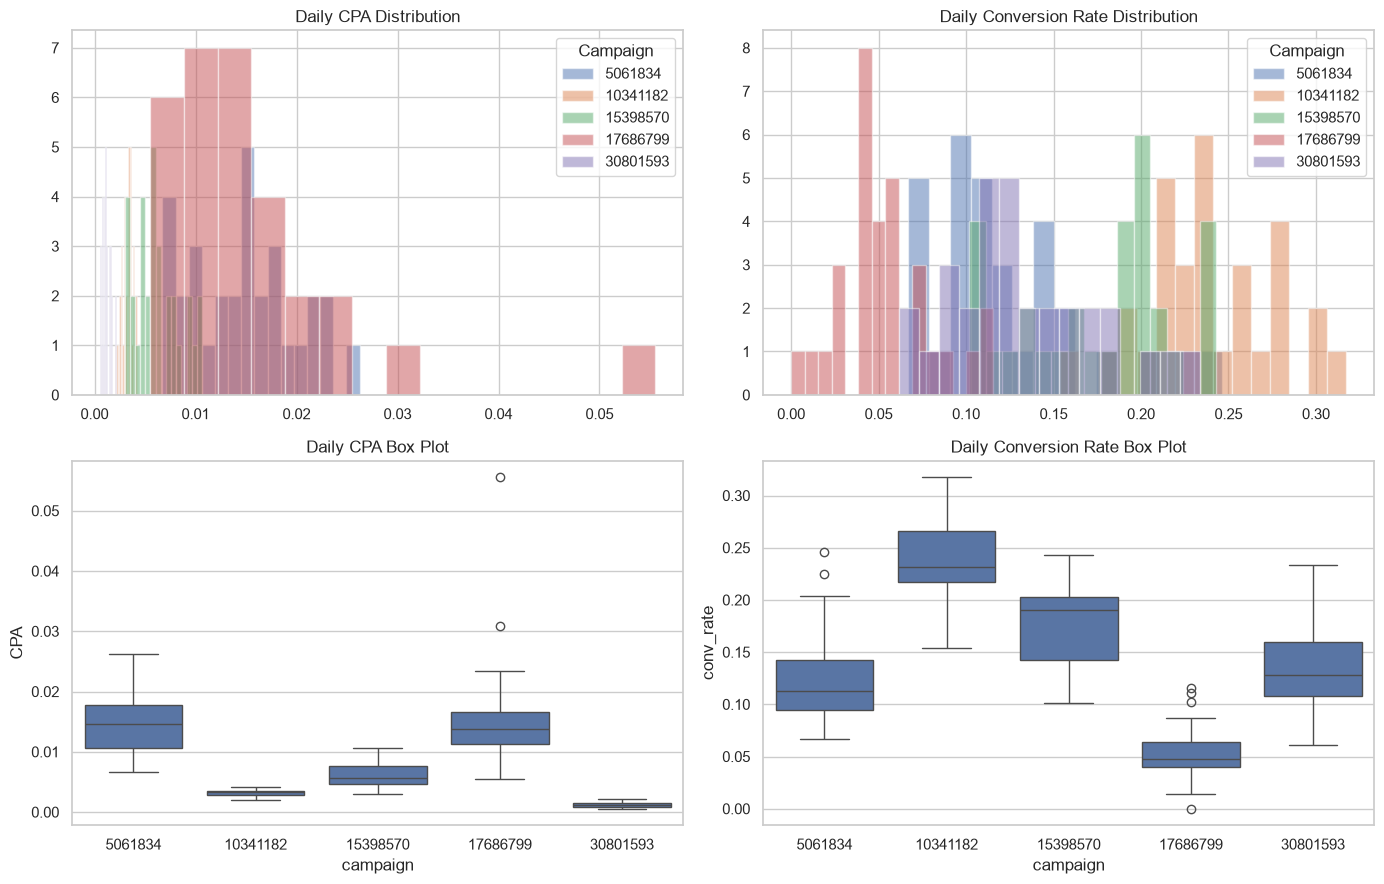

In [16]:

# Step 3.4: Visualise daily CPA and conversion rate distributions

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for campaign, group in paid.groupby("campaign"):
    axes[0, 0].hist(
        group["CPA"].dropna(),
        bins=15, alpha=0.5, label=str(campaign)
    )
    axes[0, 1].hist(
        group["conv_rate"].dropna(),
        bins=15, alpha=0.5, label=str(campaign)
    )

sns.boxplot(
    data=paid, x="campaign", y="CPA",
    ax=axes[1, 0]
)
sns.boxplot(
    data=paid, x="campaign", y="conv_rate",
    ax=axes[1, 1]
)

axes[0, 0].set_title("Daily CPA Distribution")
axes[0, 1].set_title("Daily Conversion Rate Distribution")
axes[1, 0].set_title("Daily CPA Box Plot")
axes[1, 1].set_title("Daily Conversion Rate Box Plot")

axes[0, 0].legend(title="Campaign")
axes[0, 1].legend(title="Campaign")

plt.tight_layout()
plt.savefig(OUT / "group_distributions.png", dpi=120)
plt.show()


In [17]:

# Step 3.5: Analyse daily CPA variability by campaign

variability = (
    paid.groupby("campaign")["CPA"]
    .agg(["count", "mean", "std"])
)

variability["CV"] = (
    variability["std"] /
    variability["mean"].replace(0, np.nan)
)

display(variability.round(4))


,count,mean,std,CV
campaign,,,,
5061834,31,0.0148,0.0051,0.3473
10341182,31,0.0032,0.0006,0.1733
15398570,31,0.0061,0.0022,0.3607
17686799,30,0.0154,0.0094,0.6083
30801593,31,0.0012,0.0004,0.3327


✍️ Key insights:
- Best CTR and conversion rate: Campaign 10341182 (44.86% CTR; 23.64% conversion rate).
- Lowest CPA: Campaign 30801593 (0.0011 overall CPA).
- Most consistent CPA: Campaign 10341182 (CV = 17.33%).
- Most variable CPA: Campaign 17686799 (CV = 60.83%), with two high outliers.
- Similar performance: Campaigns 5061834 and 17686799 have relatively close overall CPAs (0.0135 and 0.0132).
- Limitation: Revenue is unavailable, and costs are anonymised. Results are descriptive and require statistical testing.

💡 Statistical reminder: Each campaign's CPA is an estimate based on 31 days of sampled data (30 valid CPA values for campaign 17686799). The observed differences may reflect natural variation, so statistical testing is needed before drawing firm conclusions.

## Part 2 — Pairwise comparisons (60–75 min)
### Step 4: t-tests + Cohen's d

For every **pair** of channels: is the gap in average daily CPA bigger than the day-to-day luck?

💡 **Hints:**
- `from itertools import combinations`: `combinations(groups, 2)` gives every pair once.
- Use **Welch's t-test**: `stats.ttest_ind(b, a, equal_var=False)`. Why Welch and not the default? Look at the test table in §4b.
- Cohen's d = (mean_b − mean_a) / √((var_a + var_b) / 2). Scale: < 0.2 negligible · < 0.5 small · < 0.8 medium · ≥ 0.8 large.

In [18]:

def cohens_d(a, b):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)

    mean_diff = np.mean(b) - np.mean(a)
    pooled_sd = np.sqrt(
        (np.var(a, ddof=1) + np.var(b, ddof=1)) / 2
    )

    return mean_diff / pooled_sd if pooled_sd > 0 else np.nan


In [19]:

def effect_label(d):
    if np.isnan(d):
        return "undefined"

    d = abs(d)

    if d < 0.2:
        return "negligible"
    elif d < 0.5:
        return "small"
    elif d < 0.8:
        return "medium"
    else:
        return "large"

# Test the function
print(effect_label(0.1))
print(effect_label(0.4))
print(effect_label(0.7))
print(effect_label(1.2))


negligible
small
medium
large


In [20]:

# Step 4.3: Pairwise Welch's t-tests

def pairwise_ttests(data, metric):
    clean = data[["campaign", metric]].replace(
        [np.inf, -np.inf], np.nan
    ).dropna()

    clean = clean[clean[metric] >= 0]
    rows = []

    for a, b in combinations(
        sorted(clean["campaign"].unique()), 2
    ):
        xa = clean.loc[clean["campaign"] == a, metric]
        xb = clean.loc[clean["campaign"] == b, metric]

        t, p = stats.ttest_ind(
            xb, xa, equal_var=False
        )

        diff = xb.mean() - xa.mean()
        d = cohens_d(xa, xb)

        rows.append({
            "group_a": a,
            "group_b": b,
            "mean_a": xa.mean(),
            "mean_b": xb.mean(),
            "diff": diff,
            "pct_diff": 100 * diff / xa.mean(),
            "t_stat": t,
            "p_value": p,
            "cohens_d": d,
            "effect": effect_label(d),
            "significant": p < ALPHA
        })

    res = pd.DataFrame(rows)

    print(
        f"{metric}: {len(res)} comparisons, "
        f"{res.significant.sum()} significant"
    )

    return res

# Run the tests
cpa_res = pairwise_ttests(paid, "CPA")
cvr_res = pairwise_ttests(paid, "conv_rate")

display(cpa_res.round(4))


CPA: 10 comparisons, 9 significant
conv_rate: 10 comparisons, 9 significant


,group_a,group_b,mean_a,mean_b,diff,pct_diff,t_stat,p_value,cohens_d,effect,significant
0,5061834,10341182,0.0148,0.0032,-0.0116,-78.4138,-12.4991,0.0000,-3.1748,large,True
1,5061834,15398570,0.0148,0.0061,-0.0087,-58.6223,-8.6346,0.0000,-2.1932,large,True
2,5061834,17686799,0.0148,0.0154,0.0006,4.0414,0.3078,0.7597,0.0792,negligible,False
3,5061834,30801593,0.0148,0.0012,-0.0136,-92.0513,-14.7152,0.0000,-3.7377,large,True
4,10341182,15398570,0.0032,0.0061,0.0029,91.6854,7.1608,0.0000,1.8188,large,True
5,10341182,17686799,0.0032,0.0154,0.0122,381.9803,7.1235,0.0000,1.8392,large,True
6,10341182,30801593,0.0032,0.0012,-0.0020,-63.1769,-16.5752,0.0000,-4.2101,large,True
7,15398570,17686799,0.0061,0.0154,0.0093,151.4433,5.2825,0.0000,1.3628,large,True
8,15398570,30801593,0.0061,0.0012,-0.0050,-80.7898,-12.2778,0.0000,-3.1186,large,True
9,17686799,30801593,0.0154,0.0012,-0.0142,-92.3600,-8.3087,0.0000,-2.1452,large,True


In [21]:

# Step 4.4: Display conversion-rate comparisons
display(cvr_res.round(4))


,group_a,group_b,mean_a,mean_b,diff,pct_diff,t_stat,p_value,cohens_d,effect,significant
0,5061834,10341182,0.1224,0.2387,0.1163,94.9484,11.1816,0.0000,2.8401,large,True
1,5061834,15398570,0.1224,0.1770,0.0545,44.5342,4.9548,0.0000,1.2585,large,True
2,5061834,17686799,0.1224,0.0529,-0.0695,-56.7921,-7.5234,0.0000,-1.9109,large,True
3,5061834,30801593,0.1224,0.1333,0.0108,8.8535,0.9833,0.3294,0.2498,small,False
4,10341182,15398570,0.2387,0.1770,-0.0617,-25.8603,-6.0879,0.0000,-1.5463,large,True
5,10341182,17686799,0.2387,0.0529,-0.1858,-77.8363,-22.6768,0.0000,-5.7599,large,True
6,10341182,30801593,0.2387,0.1333,-0.1054,-44.1629,-10.3748,0.0000,-2.6352,large,True
7,15398570,17686799,0.1770,0.0529,-0.1241,-70.1054,-13.8589,0.0000,-3.5202,large,True
8,15398570,30801593,0.1770,0.1333,-0.0437,-24.6866,-4.0519,0.0001,-1.0292,large,True
9,17686799,30801593,0.0529,0.1333,0.0804,151.9299,8.9546,0.0000,2.2745,large,True


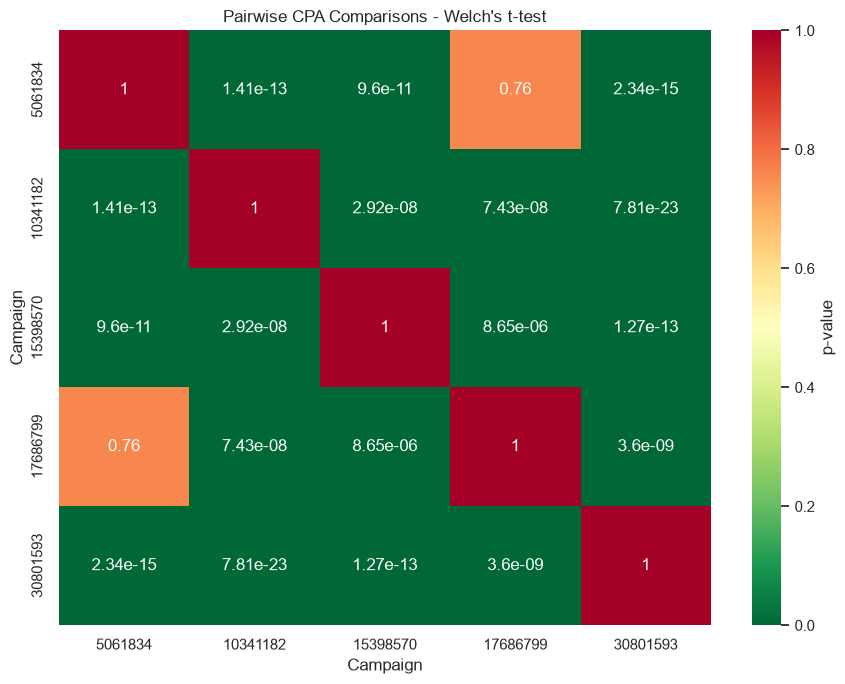

In [22]:

# Step 4.5: Heatmap of CPA p-values

campaigns = sorted(paid["campaign"].unique())

p_matrix = pd.DataFrame(
    1.0, index=campaigns, columns=campaigns
)

for _, row in cpa_res.iterrows():
    a = int(row["group_a"])
    b = int(row["group_b"])
    p_matrix.loc[a, b] = row["p_value"]
    p_matrix.loc[b, a] = row["p_value"]

plt.figure(figsize=(9, 7))

sns.heatmap(
    p_matrix,
    annot=True,
    fmt=".3g",
    cmap="RdYlGn_r",
    vmin=0,
    vmax=1.0,
    cbar_kws={"label": "p-value"}
)

plt.title("Pairwise CPA Comparisons - Welch's t-test")
plt.xlabel("Campaign")
plt.ylabel("Campaign")
plt.tight_layout()

plt.savefig(
    OUT / "metric_comparison_heatmap.png",
    dpi=120
)
plt.show()


✍️ Pairwise comparison insights: Welch's t-tests found statistically significant differences in average daily CPA for 9 of 10 campaign pairs (unadjusted p < 0.05). Only campaigns 5061834 and 17686799 could not be statistically distinguished (p = 0.7597).

💡 **Remember (§3):A big p-value means "can't tell", not "no difference".

### Step 5: Fisher's exact test on conversions (30–35 min)

Each click either converts or doesn't: **right/wrong data**, so Fisher's exact test (§4b).

```
[[conversions_A, non_conversions_A],
 [conversions_B, non_conversions_B]]
```

In [23]:

# Step 5.1: Conversion totals per campaign

conv = (
    daily_performance.groupby("campaign")[
        ["conversions", "clicks"]
    ].sum()
)

conv["non_conversions"] = (
    conv["clicks"] - conv["conversions"]
)

conv["conv_rate"] = (
    conv["conversions"] /
    conv["clicks"].replace(0, np.nan)
)

display(conv.round(4))


,conversions,clicks,non_conversions,conv_rate
campaign,,,,
5061834,213,1766,1553,0.1206
10341182,906,3832,2926,0.2364
15398570,493,2795,2302,0.1764
17686799,115,2224,2109,0.0517
30801593,440,3368,2928,0.1306


In [24]:

# Step 5.2: Pairwise Fisher's exact tests

rows = []

for a, b in combinations(sorted(conv.index), 2):
    table = [
        [int(conv.loc[a, "conversions"]),
         int(conv.loc[a, "non_conversions"])],
        [int(conv.loc[b, "conversions"]),
         int(conv.loc[b, "non_conversions"])]
    ]

    odds_ratio, p = fisher_exact(
        table, alternative="two-sided"
    )

    rate_a = conv.loc[a, "conv_rate"]
    rate_b = conv.loc[b, "conv_rate"]

    rows.append({
        "group_a": a,
        "group_b": b,
        "rate_a": rate_a,
        "rate_b": rate_b,
        "pct_diff": (rate_b - rate_a) * 100,
        "odds_ratio": odds_ratio,
        "p_value": p,
        "significant": p < ALPHA
    })

fisher_res = pd.DataFrame(rows)

print(
    "Comparisons:", len(fisher_res),
    "| Significant:", fisher_res["significant"].sum()
)

display(fisher_res.round(4))


Comparisons: 10 | Significant: 9


,group_a,group_b,rate_a,rate_b,pct_diff,odds_ratio,p_value,significant
0,5061834,10341182,0.1206,0.2364,11.5819,0.4429,0.0000,True
1,5061834,15398570,0.1206,0.1764,5.5775,0.6404,0.0000,True
2,5061834,17686799,0.1206,0.0517,-6.8903,2.5153,0.0000,True
3,5061834,30801593,0.1206,0.1306,1.0030,0.9127,0.3109,False
4,10341182,15398570,0.2364,0.1764,-6.0044,1.4458,0.0000,True
5,10341182,17686799,0.2364,0.0517,-18.4721,5.6785,0.0000,True
6,10341182,30801593,0.2364,0.1306,-10.5789,2.0605,0.0000,True
7,15398570,17686799,0.1764,0.0517,-12.4678,3.9275,0.0000,True
8,15398570,30801593,0.1764,0.1306,-4.5745,1.4251,0.0000,True
9,17686799,30801593,0.0517,0.1306,7.8933,0.3629,0.0000,True


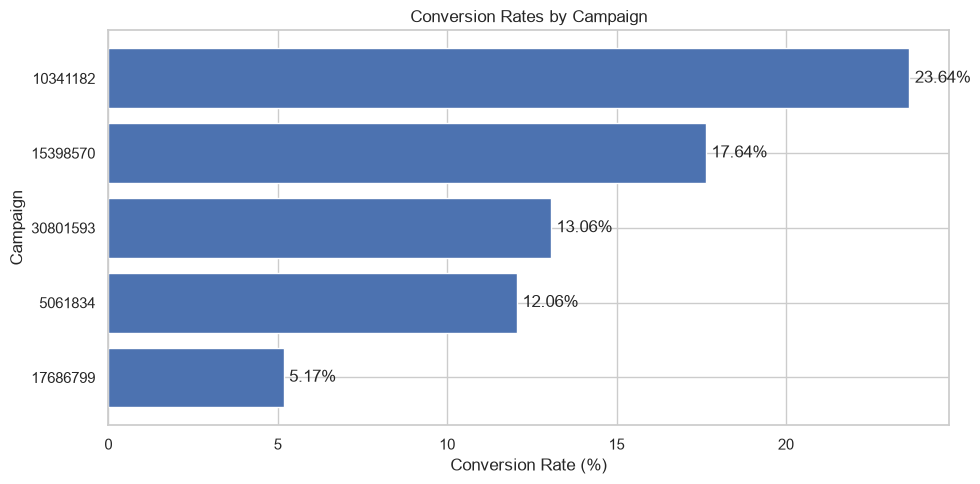

In [25]:

# Step 5.3: Conversion-rate comparison chart

rates = conv["conv_rate"].sort_values() * 100

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    rates.index.astype(str),
    rates.values
)

ax.bar_label(bars, fmt="%.2f%%", padding=4)

ax.set_xlabel("Conversion Rate (%)")
ax.set_ylabel("Campaign")
ax.set_title("Conversion Rates by Campaign")

plt.tight_layout()
plt.savefig(OUT / "rate_comparison.png", dpi=120)
plt.show()


In [26]:

# Step 5.4: Compare Fisher's test with Welch's t-test

comparison = fisher_res[
    ["group_a", "group_b", "significant"]
].merge(
    cvr_res[["group_a", "group_b", "significant"]],
    on=["group_a", "group_b"],
    suffixes=("_fisher", "_ttest")
)

comparison["disagree"] = (
    comparison["significant_fisher"] !=
    comparison["significant_ttest"]
)

display(comparison)

print("Number of disagreements:", comparison["disagree"].sum())


,group_a,group_b,significant_fisher,significant_ttest,disagree
0,5061834,10341182,True,True,False
1,5061834,15398570,True,True,False
2,5061834,17686799,True,True,False
3,5061834,30801593,False,False,False
4,10341182,15398570,True,True,False
5,10341182,17686799,True,True,False
6,10341182,30801593,True,True,False
7,15398570,17686799,True,True,False
8,15398570,30801593,True,True,False
9,17686799,30801593,True,True,False


Number of disagreements: 0


**✍️ Answer:**
1. Which channels have significantly different conversion rates?
Nine of the ten campaign pairs have statistically significant differences (p < 0.05).

2. Are the differences **large enough to matter**? Yes, some differences are substantial. Campaign 10341182 has a conversion rate of 23.64%, compared with 5.17% for Campaign 17686799 — a difference of 18.47 percentage points. However, Campaigns 5061834 and 30801593 differ by only 1 percentage point, which may have limited practical importance.

3. Fisher vs t-test: do they agree? If not, **why**? Yes. Both tests identify the same nine significant comparisons, with zero disagreements.

💡 Which campaign performs best?
Campaign 10341182 has the highest conversion rate (23.64%), while Campaign 17686799 has the lowest (5.17%).

Conclusion: The results provide strong evidence of differences in conversion performance across most campaign pairs. However, statistical significance alone does not establish profitability or justify a budget allocation.

## Part 3 — Multiple comparisons correction (45–60 min)
### Step 6: Bonferroni and Benjamini-Hochberg

💡 **Hints (§8 of the statistics notebook):**
- Bonferroni: significant if `p < ALPHA / number_of_tests`
- BH: `false_discovery_control(p_values, method="bh")` returns **adjusted** p-values; significant if adjusted < ALPHA

In [27]:

# Step 6.1: Count tests and expected false positives

families = {
    "CPA (t-test)": cpa_res,
    "Conv. rate (t-test)": cvr_res,
    "Conv. rate (Fisher)": fisher_res
}

total_tests = sum(len(res) for res in families.values())
expected_false_positives = total_tests * ALPHA

print("Total statistical tests:", total_tests)
print("Expected false positives:", expected_false_positives)
print("Bonferroni threshold per family:", ALPHA / 10)


Total statistical tests: 30
Expected false positives: 1.5
Bonferroni threshold per family: 0.005


In [28]:

# Step 6.2: Apply Bonferroni correction

for name, res in families.items():
    m = len(res)
    res["significant_bonferroni"] = (
        res["p_value"] < ALPHA / m
    )

    print(
        name,
        "| Before:", res["significant"].sum(),
        "| After Bonferroni:", res["significant_bonferroni"].sum()
    )


CPA (t-test) | Before: 9 | After Bonferroni: 9
Conv. rate (t-test) | Before: 9 | After Bonferroni: 9
Conv. rate (Fisher) | Before: 9 | After Bonferroni: 9


In [29]:

# Step 6.3: Apply Benjamini-Hochberg correction

for name, res in families.items():
    res["p_value_fdr"] = false_discovery_control(
        res["p_value"].to_numpy(),
        method="bh"
    )

    res["significant_fdr"] = res["p_value_fdr"] < ALPHA

    print(
        name,
        "| Before:", res["significant"].sum(),
        "| After BH:", res["significant_fdr"].sum()
    )


CPA (t-test) | Before: 9 | After BH: 9
Conv. rate (t-test) | Before: 9 | After BH: 9
Conv. rate (Fisher) | Before: 9 | After BH: 9


In [30]:

# Step 6.4: Summary of multiple-comparison corrections

rows = []

for name, res in families.items():
    rows.append({
        "family": name,
        "tests": len(res),
        "uncorrected": int(res["significant"].sum()),
        "Bonferroni": int(res["significant_bonferroni"].sum()),
        "BH-FDR": int(res["significant_fdr"].sum())
    })

correction_summary = pd.DataFrame(rows).set_index("family")

display(correction_summary)


,tests,uncorrected,Bonferroni,BH-FDR
family,,,,
CPA (t-test),10,9,9,9
Conv. rate (t-test),10,9,9,9
Conv. rate (Fisher),10,9,9,9


In [31]:

# Step 6.5: Identify comparisons that lost significance

for name, res in families.items():
    lost_bonf = res[
        res["significant"] & ~res["significant_bonferroni"]
    ]

    lost_bh = res[
        res["significant"] & ~res["significant_fdr"]
    ]

    print(f"\n{name}")
    print("Lost significance after Bonferroni:", len(lost_bonf))
    print("Lost significance after BH:", len(lost_bh))

    if not lost_bonf.empty:
        display(lost_bonf[["group_a", "group_b", "p_value"]])

    if not lost_bh.empty:
        display(lost_bh[["group_a", "group_b", "p_value"]])



CPA (t-test)
Lost significance after Bonferroni: 0
Lost significance after BH: 0

Conv. rate (t-test)
Lost significance after Bonferroni: 0
Lost significance after BH: 0

Conv. rate (Fisher)
Lost significance after Bonferroni: 0
Lost significance after BH: 0


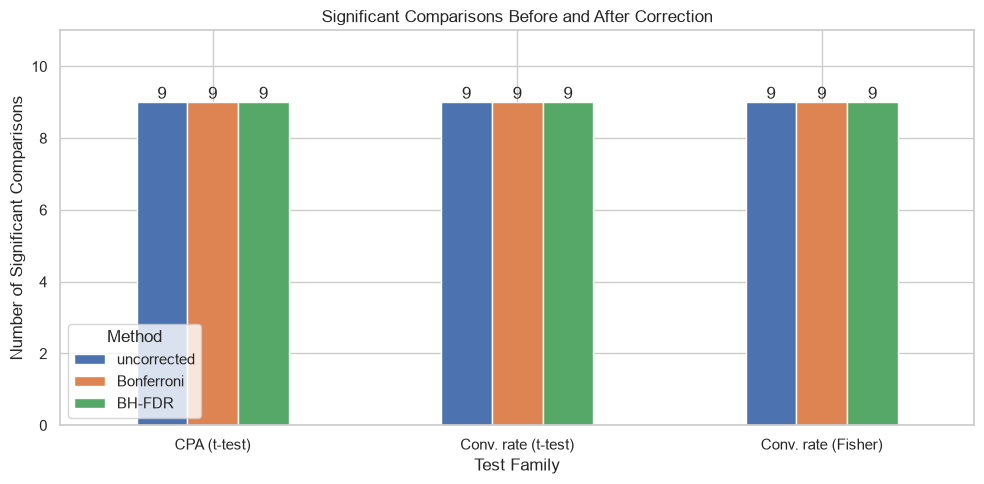

In [32]:

# Step 6.6: Compare significance before and after correction

ax = correction_summary[
    ["uncorrected", "Bonferroni", "BH-FDR"]
].plot(kind="bar", figsize=(10, 5))

ax.set_title("Significant Comparisons Before and After Correction")
ax.set_xlabel("Test Family")
ax.set_ylabel("Number of Significant Comparisons")
ax.set_ylim(0, 11)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Method")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.savefig(OUT / "correction_comparison.png", dpi=120)
plt.show()


**✍️ Answer:**
1. How many "significant" results disappeared after correction? None. All 27 significant results remained significant after both Bonferroni and Benjamini–Hochberg corrections.

2. Which correction fits a **budget decision**, and why? Bonferroni is more conservative and suitable when selecting a false winner could lead to costly budget decisions. Benjamini–Hochberg is useful when exploring several promising campaigns.

3. What does this mean for moving budget? The statistical differences are robust, but budget changes should remain cautious. Revenue data is unavailable, and advertising costs are anonymised, so profitability cannot be established.

## Part 4 — Power analysis (30–45 min)
### Step 7: Do we have enough data?

**Power** = the chance of catching a difference that is **really** there (§5). Simulate many experiments where you **know** the truth:
- channel A: daily CPA ~ normal(mean = `base_cpa`, std = 15% of `base_cpa`)
- channel B: the same, but mean = `base_cpa × (1 + true_diff_pct)`
- cap low values at 50% of `base_cpa` (`np.maximum(x, 0.5 * base_cpa)`)
- t-test → count how often p < 0.05

💡 **Speed hint:** draw all simulations at once with shape `(n_sim, n_days)` and use `stats.ttest_ind(a, b, axis=1)`. A plain loop also works, but use `n_sim=300` then.

In [33]:
# Step 7.1: Simulate statistical power for CPA differences

def empirical_power_cpa(true_diff_pct, base_cpa, n_days,
                        n_sim=1000, alpha=0.05):

    rng = np.random.default_rng(42)

    std = 0.15 * base_cpa

    a = rng.normal(
        loc=base_cpa,
        scale=std,
        size=(n_sim, n_days)
    )

    b = rng.normal(
        loc=base_cpa * (1 + true_diff_pct),
        scale=std,
        size=(n_sim, n_days)
    )

    a = np.maximum(a, 0.5 * base_cpa)
    b = np.maximum(b, 0.5 * base_cpa)

    _, p_values = stats.ttest_ind(
        a, b, axis=1, equal_var=False
    )

    return np.mean(p_values < alpha)


# Test the function
print("Estimated power:",
      empirical_power_cpa(0.10, 0.01, 31))

Estimated power: 0.688


In [34]:
# Step 7.2: Power across effect sizes and sample sizes

BASE_CPA = paid["CPA"].median()

effects = [0.05, 0.10, 0.15, 0.20]
days = [30, 60, 90, 120, 180]

rows = []

for effect in effects:
    for n in days:
        power = empirical_power_cpa(
            effect, BASE_CPA, n
        )

        rows.append({
            "effect_size_pct": effect * 100,
            "n_days": n,
            "power": power
        })

power_df = pd.DataFrame(rows)

display(power_df.round(3))

,effect_size_pct,n_days,power
0,5.0,30,0.240
1,5.0,60,0.431
2,5.0,90,0.585
3,5.0,120,0.756
4,5.0,180,0.884
5,10.0,30,0.701
6,10.0,60,0.945
7,10.0,90,0.992
8,10.0,120,0.999
9,10.0,180,1.000


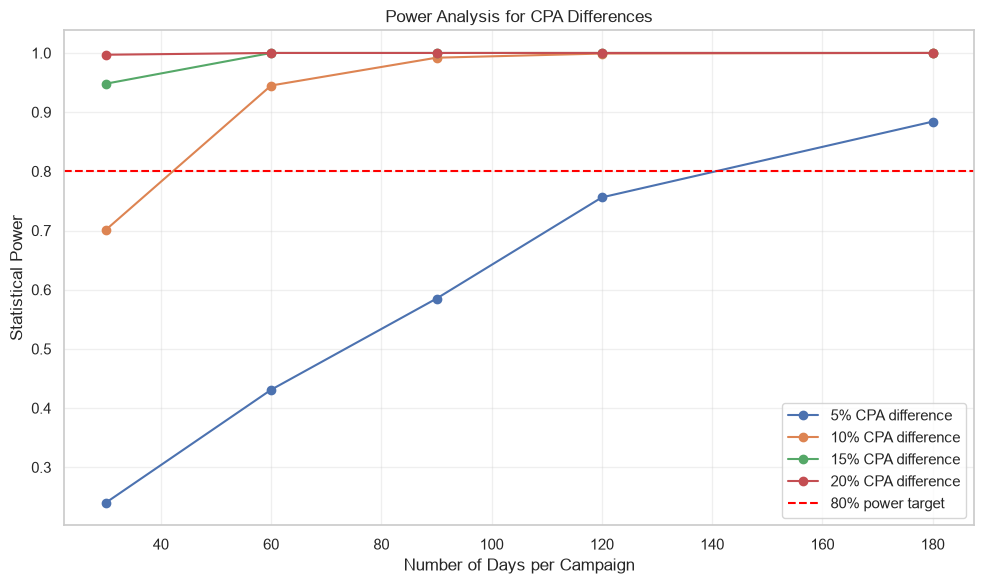

In [35]:
# Step 7.3: Plot statistical power

plt.figure(figsize=(10, 6))

for effect in sorted(power_df["effect_size_pct"].unique()):
    subset = power_df[
        power_df["effect_size_pct"] == effect
    ]

    plt.plot(
        subset["n_days"],
        subset["power"],
        marker="o",
        label=f"{effect:.0f}% CPA difference"
    )

plt.axhline(
    y=0.8,
    color="red",
    linestyle="--",
    label="80% power target"
)

plt.xlabel("Number of Days per Campaign")
plt.ylabel("Statistical Power")
plt.title("Power Analysis for CPA Differences")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(OUT / "power_analysis_cpa.png", dpi=120)
plt.show()

In [36]:
# Step 7.4: Minimum days needed for 80% power

minimum_days = (
    power_df[power_df["power"] >= 0.80]
    .groupby("effect_size_pct")["n_days"]
    .min()
)

summary = pd.DataFrame({
    "minimum_days": minimum_days
})

summary["current_days"] = 31

summary["status"] = np.where(
    summary["current_days"] >= summary["minimum_days"],
    "sufficient",
    "insufficient"
)

display(summary)

,minimum_days,current_days,status
effect_size_pct,,,
5.0,180,31,insufficient
10.0,60,31,insufficient
15.0,30,31,sufficient
20.0,30,31,sufficient


In [37]:
# Step 7.5: Power for significant CPA comparisons

significant_pairs = cpa_res[
    cpa_res["significant_fdr"]
].copy()

results = []

for _, row in significant_pairs.iterrows():
    baseline = min(row["mean_a"], row["mean_b"])
    difference = abs(row["mean_b"] - row["mean_a"])
    effect = difference / baseline

    observed_power = empirical_power_cpa(
        effect, baseline, 31
    )

    results.append({
        "campaign_a": int(row["group_a"]),
        "campaign_b": int(row["group_b"]),
        "difference_pct": effect * 100,
        "true_diff_pct": effect,
        "base_cpa": baseline,
        "power_31_days": observed_power,
        "status": (
            "sufficient" if observed_power >= 0.80
            else "insufficient"
        )
    })

pair_power = pd.DataFrame(results)

display(pair_power.round(3))

,campaign_a,campaign_b,difference_pct,true_diff_pct,base_cpa,power_31_days,status
0,5061834,10341182,363.258,3.633,0.003,1.0,sufficient
1,5061834,15398570,141.676,1.417,0.006,1.0,sufficient
2,5061834,30801593,1158.064,11.581,0.001,1.0,sufficient
3,10341182,15398570,91.685,0.917,0.003,1.0,sufficient
4,10341182,17686799,381.980,3.820,0.003,1.0,sufficient
5,10341182,30801593,171.569,1.716,0.001,1.0,sufficient
6,15398570,17686799,151.443,1.514,0.006,1.0,sufficient
7,15398570,30801593,420.558,4.206,0.001,1.0,sufficient
8,17686799,30801593,1208.908,12.089,0.001,1.0,sufficient


In [38]:


# Step 7.6: Estimate additional days needed for 80% power

def minimum_days_for_power(true_diff_pct, base_cpa,
                           current_days=31, target_power=0.80,
                           max_days=365):
    for n_days in range(current_days, max_days + 1):
        power = empirical_power_cpa(
            true_diff_pct, base_cpa, n_days
        )
        if power >= target_power:
            return n_days - current_days

    return np.nan  # Target not reached within 365 days


additional_days = []

for _, row in pair_power.iterrows():
    if row["power_31_days"] >= 0.80:
        additional_days.append(0)
    else:
        days = minimum_days_for_power(
            row["true_diff_pct"],
            row["base_cpa"]
        )
        additional_days.append(days)

pair_power["additional_days"] = additional_days

print("Comparisons below 80% power:",
      (pair_power["power_31_days"] < 0.80).sum())

display(pair_power[[
    "campaign_a",
    "campaign_b",
    "power_31_days",
    "additional_days"
]])


Comparisons below 80% power: 0


,campaign_a,campaign_b,power_31_days,additional_days
0,5061834,10341182,1.0,0
1,5061834,15398570,1.0,0
2,5061834,30801593,1.0,0
3,10341182,15398570,1.0,0
4,10341182,17686799,1.0,0
5,10341182,30801593,1.0,0
6,15398570,17686799,1.0,0
7,15398570,30801593,1.0,0
8,17686799,30801593,1.0,0


**✍️ Answer:**
1. What size of CPA difference can your data detect reliably? 

With 31 daily observations per campaign, the simulation suggests we can reliably detect CPA differences of approximately 15% or greater, assuming 15% daily variability.

2. How many days would you need to detect a 5% difference?

Approximately 180 days per campaign, based on the tested sample sizes and the 80% power target.

3. Look at your non-significant pairs: "no difference" or "not enough data"?

We cannot conclude that non-significant pairs are identical. The CPA comparison between Campaigns 5061834 and 17686799 was not statistically significant (p ≈ 0.76). Their observed CPA difference was approximately 4%, which is below what our 31-day simulation can reliably detect. More observations would be needed to investigate such a small difference.!

💡 **Remember:** half the difference → about **4× the data**.

## Part 5 — Business recommendations (30–45 min)
### Step 8: From statistics to a decision

In [39]:

# Step 8.1: Summary of significant findings (BH-corrected)

print("CPA comparisons:")
display(
    cpa_res.loc[
        cpa_res["significant_fdr"],
        ["group_a", "group_b", "mean_a", "mean_b",
         "diff", "p_value_fdr", "cohens_d"]
    ].round(4)
)

print("Conversion rate comparisons:")
display(
    cvr_res.loc[
        cvr_res["significant_fdr"],
        ["group_a", "group_b", "mean_a", "mean_b",
         "diff", "p_value_fdr"]
    ].round(4)
)


CPA comparisons:


,group_a,group_b,mean_a,mean_b,diff,p_value_fdr,cohens_d
0,5061834,10341182,0.0148,0.0032,-0.0116,0.0,-3.1748
1,5061834,15398570,0.0148,0.0061,-0.0087,0.0,-2.1932
3,5061834,30801593,0.0148,0.0012,-0.0136,0.0,-3.7377
4,10341182,15398570,0.0032,0.0061,0.0029,0.0,1.8188
5,10341182,17686799,0.0032,0.0154,0.0122,0.0,1.8392
6,10341182,30801593,0.0032,0.0012,-0.0020,0.0,-4.2101
7,15398570,17686799,0.0061,0.0154,0.0093,0.0,1.3628
8,15398570,30801593,0.0061,0.0012,-0.0050,0.0,-3.1186
9,17686799,30801593,0.0154,0.0012,-0.0142,0.0,-2.1452


Conversion rate comparisons:


,group_a,group_b,mean_a,mean_b,diff,p_value_fdr
0,5061834,10341182,0.1224,0.2387,0.1163,0.0000
1,5061834,15398570,0.1224,0.1770,0.0545,0.0000
2,5061834,17686799,0.1224,0.0529,-0.0695,0.0000
4,10341182,15398570,0.2387,0.1770,-0.0617,0.0000
5,10341182,17686799,0.2387,0.0529,-0.1858,0.0000
6,10341182,30801593,0.2387,0.1333,-0.1054,0.0000
7,15398570,17686799,0.1770,0.0529,-0.1241,0.0000
8,15398570,30801593,0.1770,0.1333,-0.0437,0.0002
9,17686799,30801593,0.0529,0.1333,0.0804,0.0000


In [40]:

# Step 8.2: Bootstrap confidence interval function

def bootstrap_ci(data, n_bootstrap=1000, ci_level=0.95):
    values = np.asarray(data, dtype=float)
    values = values[np.isfinite(values)]

    rng = np.random.default_rng(42)

    bootstrap_means = [
        rng.choice(values, size=len(values), replace=True).mean()
        for _ in range(n_bootstrap)
    ]

    alpha = 1 - ci_level

    return np.percentile(
        bootstrap_means,
        [100 * alpha / 2, 100 * (1 - alpha / 2)]
    )

# Test with one campaign
sample = paid.loc[paid["campaign"] == 5061834, "CPA"]

print("95% confidence interval:", bootstrap_ci(sample))


95% confidence interval: [0.01300179 0.01660164]


In [41]:
# Step 8.2a: Bootstrap 95% confidence intervals for all campaigns

ci_results = []

for campaign, group in paid.groupby("campaign"):
    for metric in ["CPA", "conv_rate"]:
        values = group[metric].dropna()

        if len(values) > 1:
            lower, upper = bootstrap_ci(values)

            ci_results.append({
                "campaign": campaign,
                "metric": metric,
                "mean": values.mean(),
                "CI_lower": lower,
                "CI_upper": upper
            })

ci_table = pd.DataFrame(ci_results)

display(ci_table.round(6))

,campaign,metric,mean,CI_lower,CI_upper
0,5061834,CPA,0.014811,0.013002,0.016602
1,5061834,conv_rate,0.122436,0.107586,0.139509
2,10341182,CPA,0.003197,0.003020,0.003384
3,10341182,conv_rate,0.238687,0.226461,0.251371
4,15398570,CPA,0.006129,0.005341,0.006943
5,15398570,conv_rate,0.176962,0.161310,0.191733
6,17686799,CPA,0.015410,0.012477,0.018774
7,17686799,conv_rate,0.052902,0.044017,0.062133
8,30801593,CPA,0.001177,0.001041,0.001337
9,30801593,conv_rate,0.133276,0.118318,0.149019


In [42]:

# Step 8.3: CPA confidence intervals for all campaigns

rows = []

for campaign, group in paid.groupby("campaign"):
    low, high = bootstrap_ci(group["CPA"])

    rows.append({
        "campaign": campaign,
        "mean_daily_CPA": group["CPA"].mean(),
        "CI_95_low": low,
        "CI_95_high": high
    })

ci_summary = pd.DataFrame(rows)

display(ci_summary.round(4))


,campaign,mean_daily_CPA,CI_95_low,CI_95_high
0,5061834,0.0148,0.0130,0.0166
1,10341182,0.0032,0.0030,0.0034
2,15398570,0.0061,0.0053,0.0069
3,17686799,0.0154,0.0125,0.0188
4,30801593,0.0012,0.0010,0.0013


In [43]:

# Step 8.4: Provisional CPA-only ranking
# ROAS unavailable because revenue is missing

ranking = ci_summary.copy()

ranking["CPA_rank"] = ranking["mean_daily_CPA"].rank(
    ascending=False,
    method="average"
)

ranking = ranking.sort_values(
    "CPA_rank", ascending=False
)

display(ranking[
    ["campaign", "mean_daily_CPA", "CPA_rank"]
].round(4))


,campaign,mean_daily_CPA,CPA_rank
4,30801593,0.0012,5.0
1,10341182,0.0032,4.0
2,15398570,0.0061,3.0
0,5061834,0.0148,2.0
3,17686799,0.0154,1.0


In [44]:

# Step 8.5: Provisional budget allocation

TOTAL_BUDGET = 500000

# Higher CPA rank means better performance (lower CPA)
ranking["allocation_pct"] = (
    ranking["CPA_rank"] / ranking["CPA_rank"].sum()
)

# Check that all allocations respect the limits
assert ranking["allocation_pct"].between(0.05, 0.35).all()

ranking["budget_USD"] = (
    ranking["allocation_pct"] * TOTAL_BUDGET
)

display(
    ranking[
        ["campaign", "mean_daily_CPA", "CPA_rank",
         "allocation_pct", "budget_USD"]
    ].round(4)
)

print("Total allocated:", ranking["budget_USD"].sum())

,campaign,mean_daily_CPA,CPA_rank,allocation_pct,budget_USD
4,30801593,0.0012,5.0,0.3333,166666.6667
1,10341182,0.0032,4.0,0.2667,133333.3333
2,15398570,0.0061,3.0,0.2000,100000.0000
0,5061834,0.0148,2.0,0.1333,66666.6667
3,17686799,0.0154,1.0,0.0667,33333.3333


Total allocated: 500000.0


In [45]:

# Step 8.6: Create and save the executive memo

from IPython.display import Markdown, display
from datetime import date

allocation_table = ranking[
    ["campaign", "allocation_pct", "budget_USD"]
].copy()

allocation_table["allocation_pct"] = allocation_table["allocation_pct"].map(
    lambda x: f"{x:.2%}"
)
allocation_table["budget_USD"] = allocation_table["budget_USD"].map(
    lambda x: f"${x:,.2f}"
)

budget_rows = "\n".join(
    f"| {row.campaign} | {row.allocation_pct} | {row.budget_USD} |"
    for row in allocation_table.itertuples(index=False)
)

memo = f"""# Executive Memo — Marketing Budget Allocation

**To:** Chief Marketing Officer  
**From:** Marketing Analytics Team  
**Date:** {date.today().isoformat()}  
**Dataset:** Criteo advertising campaign data  
**Analysis period:** 31 daily observations per campaign (one campaign has 30 valid CPA observations)

## Executive Summary

Analysis of five advertising campaigns identified substantial differences
in cost per acquisition (CPA) and conversion performance.

Campaign 30801593 has the lowest average daily CPA (0.0012).
Campaign 10341182 has the highest overall conversion rate (23.64%).

A provisional allocation of $500,000 is proposed using CPA rankings.
This is a planning scenario, not a revenue-validated budget decision.

## Key Findings

- CPA: 9 of 10 pairwise comparisons were statistically significant.
- Conversion rates: 9 of 10 comparisons were significant.
- Both Bonferroni and Benjamini-Hochberg corrections retained all 9 significant comparisons in each test family.
- Fisher's exact test and Welch's t-test agreed on all 10 conversion-rate comparisons.
- Campaigns 5061834 and 17686799 had no statistically significant CPA difference (p approximately 0.76).
- Campaigns 5061834 and 30801593 had no statistically significant conversion-rate difference.
- The 95% bootstrap CPA confidence interval for campaign 30801593 was approximately 0.0010–0.0013.
- The power simulation suggests 31 days are sufficient for detecting differences of approximately 15–20% under its assumptions, but insufficient for reliable detection of 5–10% differences.

## Provisional Monthly Budget Allocation

| Campaign | Allocation | Budget |
|---|---:|---:|
{budget_rows}
| **Total** | **100%** | **$500,000.00** |

The allocation uses CPA-only rankings because revenue data
is unavailable. Each campaign receives between 5% and 35%.

## Recommendations

1. Prioritise campaign 30801593 for further investment testing because it has the lowest observed CPA.
2. Retain campaign 10341182 as a priority because it has the highest conversion rate.
3. Monitor campaigns 5061834 and 17686799 before making strong claims about their relative CPA performance.
4. Validate the proposed allocations through controlled budget increases rather than immediately committing the full amounts.

## Statistical Caveats

- **Dataset limitations:** Advertising costs are anonymised, and revenue is unavailable. Actual dollar CPA, ROAS, profit and profit margin cannot be established.
- **Multiple comparisons:** Bonferroni and BH-FDR corrections were applied separately to each family of ten comparisons.
- **Confidence intervals:** Bootstrap intervals quantify uncertainty in average daily CPA under the sampling assumptions.
- **Power:** Simulated power depends on assumed variability and effect sizes; it is not a guarantee of real-world performance.
- **External factors:** Audience targeting, seasonality, attribution, campaign overlap and diminishing returns may influence results.
- **Budget limitation:** The $500,000 allocation is illustrative and cannot be validated against actual spending capacity or revenue.

## Next Steps

1. Obtain reliable revenue and non-anonymised cost data.
2. Recalculate CPA, ROAS and profitability.
3. Test incremental budget increases and monitor marginal performance.
4. Reassess the allocation using observed financial returns and confidence intervals.
"""

# Add confidence intervals for all five campaigns
ci_display = ci_table.copy()
ci_display["mean"] = ci_display["mean"].round(6)
ci_display["CI_lower"] = ci_display["CI_lower"].round(6)
ci_display["CI_upper"] = ci_display["CI_upper"].round(6)

ci_section = (
    "\n## Bootstrap 95% Confidence Intervals\n\n"
    "Intervals are based on mean daily CPA and mean daily "
    "conversion rate (conversions / clicks).\n\n"
    + ci_display.to_markdown(index=False)
    + "\n\n"
)

memo = memo.replace(
    "## Provisional Monthly Budget Allocation",
    ci_section + "## Provisional Monthly Budget Allocation"
)

# Explain the budget allocation method
budget_explanation = (
    "\n**Allocation method:** Campaigns were ranked by observed mean daily CPA. "
    "Lower CPA received a higher ranking score and therefore a larger share "
    "of the $500,000 budget. The resulting allocations range from 6.67% "
    "to 33.33%, within the required 5%–35% limits. "
    "Because revenue is unavailable, ROAS was not used. "
    "Budget increases should be tested incrementally before full implementation.\n"
)

memo = memo.replace(
    "## Recommendations",
    budget_explanation + "\n## Recommendations"
)

(OUT / "executive_memo.md").write_text(memo, encoding="utf-8")

display(Markdown(memo))

print("Saved:", OUT / "executive_memo.md")


# Executive Memo — Marketing Budget Allocation

**To:** Chief Marketing Officer  
**From:** Marketing Analytics Team  
**Date:** 2026-11-24  
**Dataset:** Criteo advertising campaign data  
**Analysis period:** 31 daily observations per campaign (one campaign has 30 valid CPA observations)

## Executive Summary

Analysis of five advertising campaigns identified substantial differences
in cost per acquisition (CPA) and conversion performance.

Campaign 30801593 has the lowest average daily CPA (0.0012).
Campaign 10341182 has the highest overall conversion rate (23.64%).

A provisional allocation of $500,000 is proposed using CPA rankings.
This is a planning scenario, not a revenue-validated budget decision.

## Key Findings

- CPA: 9 of 10 pairwise comparisons were statistically significant.
- Conversion rates: 9 of 10 comparisons were significant.
- Both Bonferroni and Benjamini-Hochberg corrections retained all 9 significant comparisons in each test family.
- Fisher's exact test and Welch's t-test agreed on all 10 conversion-rate comparisons.
- Campaigns 5061834 and 17686799 had no statistically significant CPA difference (p approximately 0.76).
- Campaigns 5061834 and 30801593 had no statistically significant conversion-rate difference.
- The 95% bootstrap CPA confidence interval for campaign 30801593 was approximately 0.0010–0.0013.
- The power simulation suggests 31 days are sufficient for detecting differences of approximately 15–20% under its assumptions, but insufficient for reliable detection of 5–10% differences.


## Bootstrap 95% Confidence Intervals

Intervals are based on mean daily CPA and mean daily conversion rate (conversions / clicks).

|   campaign | metric    |     mean |   CI_lower |   CI_upper |
|-----------:|:----------|---------:|-----------:|-----------:|
|    5061834 | CPA       | 0.014811 |   0.013002 |   0.016602 |
|    5061834 | conv_rate | 0.122436 |   0.107586 |   0.139509 |
|   10341182 | CPA       | 0.003197 |   0.00302  |   0.003384 |
|   10341182 | conv_rate | 0.238687 |   0.226461 |   0.251371 |
|   15398570 | CPA       | 0.006129 |   0.005341 |   0.006943 |
|   15398570 | conv_rate | 0.176962 |   0.16131  |   0.191733 |
|   17686799 | CPA       | 0.01541  |   0.012477 |   0.018774 |
|   17686799 | conv_rate | 0.052902 |   0.044017 |   0.062133 |
|   30801593 | CPA       | 0.001177 |   0.001041 |   0.001337 |
|   30801593 | conv_rate | 0.133276 |   0.118318 |   0.149019 |

## Provisional Monthly Budget Allocation

| Campaign | Allocation | Budget |
|---|---:|---:|
| 30801593 | 33.33% | $166,666.67 |
| 10341182 | 26.67% | $133,333.33 |
| 15398570 | 20.00% | $100,000.00 |
| 5061834 | 13.33% | $66,666.67 |
| 17686799 | 6.67% | $33,333.33 |
| **Total** | **100%** | **$500,000.00** |

The allocation uses CPA-only rankings because revenue data
is unavailable. Each campaign receives between 5% and 35%.


**Allocation method:** Campaigns were ranked by observed mean daily CPA. Lower CPA received a higher ranking score and therefore a larger share of the $500,000 budget. The resulting allocations range from 6.67% to 33.33%, within the required 5%–35% limits. Because revenue is unavailable, ROAS was not used. Budget increases should be tested incrementally before full implementation.

## Recommendations

1. Prioritise campaign 30801593 for further investment testing because it has the lowest observed CPA.
2. Retain campaign 10341182 as a priority because it has the highest conversion rate.
3. Monitor campaigns 5061834 and 17686799 before making strong claims about their relative CPA performance.
4. Validate the proposed allocations through controlled budget increases rather than immediately committing the full amounts.

## Statistical Caveats

- **Dataset limitations:** Advertising costs are anonymised, and revenue is unavailable. Actual dollar CPA, ROAS, profit and profit margin cannot be established.
- **Multiple comparisons:** Bonferroni and BH-FDR corrections were applied separately to each family of ten comparisons.
- **Confidence intervals:** Bootstrap intervals quantify uncertainty in average daily CPA under the sampling assumptions.
- **Power:** Simulated power depends on assumed variability and effect sizes; it is not a guarantee of real-world performance.
- **External factors:** Audience targeting, seasonality, attribution, campaign overlap and diminishing returns may influence results.
- **Budget limitation:** The $500,000 allocation is illustrative and cannot be validated against actual spending capacity or revenue.

## Next Steps

1. Obtain reliable revenue and non-anonymised cost data.
2. Recalculate CPA, ROAS and profitability.
3. Test incremental budget increases and monitor marginal performance.
4. Reassess the allocation using observed financial returns and confidence intervals.


Saved: outputs\executive_memo.md


In [46]:

# Step 8.6: Add decision considerations to the executive memo

decision_considerations = """
- **Ranking fairness:** Campaigns 5061834 and 17686799 have no statistically significant difference in daily CPA (p = 0.7597). Their different CPA rankings do not prove that one is better.
- **Budget scalability:** Campaign 30801593 has the lowest observed CPA and receives the highest proposed allocation. However, we cannot confirm that it can absorb a larger budget while maintaining the same CPA.
- **Practical significance:** Statistical significance does not automatically mean financial importance. Differences must be assessed against actual spending, revenue, profitability and business impact before reallocating budgets.
"""

# Insert after Practical significance and before Power
lines = memo.splitlines()
insert_at = next(
    (i for i, line in enumerate(lines)
     if line.strip().startswith("- **Power:**")),
    None
)

if insert_at is None:
    raise ValueError("Could not find the Power bullet in Statistical Caveats.")

# Avoid adding the same text twice
if "**Ranking fairness:**" not in memo:
    lines[insert_at:insert_at] = decision_considerations.strip().splitlines()
    memo = "\n".join(lines) + "\n"

# Save updated memo
(OUT / "executive_memo.md").write_text(memo, encoding="utf-8")

print("Updated:", OUT / "executive_memo.md")


Updated: outputs\executive_memo.md


💡 **Before you write the memo, think:**
- Two channels whose CPA difference is **not significant** still get different ranks. Is that fair?
- The top channel may be **small**. Can it really absorb a big budget at the same CPA?
- Which "significant" differences are **too small to matter**?

## Reflection (optional, recommended): `reflection.md`
1. What surprised you about the results? 9 of 10 campaign comparisons were significant
2. How did multiple-comparison correction change your conclusions? Bonferroni and BH-FDR did not change our conclusions.
3. What are the limits of this analysis? Missing revenue, anonymised costs, and uncertainty about scaling budgets.
4. How would you explain the findings to a non-technical CMO in one minute? Explain which campaigns performed better, the proposed budget allocation, and why further validation is necessary.

## Submission checklist
- [ ] GitHub repo with only this lab, plus a `README.md` (how to run + file map)
- [ ] `lab_proof.md` as the entry point (code/workflow, one run with its input, the evidence, the final output, one failure or limitation you hit)
- [ ] Notebook(s) run top to bottom without errors
- [ ] `outputs/`: `marketing_data.csv`, the 5 charts, `executive_memo.md`